# **Aerial image classification · Bird or Drone**

# Shanmukha Pranay · Individual project

Given one photograph, predict its class and show the model's confidence. Compare a CNN trained from scratch with a fine-tuned MobileNetV2. Each picture receives one label.

**Start here in Colab.** Select **Runtime → Change runtime type → T4 GPU** if available. Choose **Runtime → Run all**. At the upload prompt select the three original train, valid and test ZIP files together. The pretrained model requires internet on its first run.

## 1 · Load the course images
The folder names supply the labels. This cell checks that each split matches the instructor’s counts before training. You can also put the three ZIPs directly in Colab’s Files panel.

In [1]:
from pathlib import Path, PurePosixPath
from zipfile import ZipFile
from collections import Counter
import shutil
from google.colab import files

ROOT = Path('/content')
DATA = ROOT / 'bird_drone_dataset'
CLASSES = ['bird', 'drone']
EXPECTED = {'train': [1414, 1248], 'valid': [217, 225], 'test': [121, 94]}

def counts(split):
    return [len(list((DATA / split / name).glob('*.jpg'))) for name in CLASSES]

if any(counts(split) != target for split, target in EXPECTED.items()):
    archives = list(ROOT.glob('*.zip'))
    if not all(any(p.name.startswith(s) for p in archives) for s in EXPECTED):
        uploaded = files.upload()
        archives = [Path(p).resolve() for p in uploaded]
        del uploaded
    for archive in archives:
        if not archive.name.startswith(tuple(EXPECTED)):
            continue
        with ZipFile(archive) as z:
            for member in z.infolist():
                parts = PurePosixPath(member.filename).parts
                if len(parts) != 3 or parts[0] not in EXPECTED or parts[1] not in CLASSES:
                    continue
                if not parts[2].lower().endswith('.jpg'):
                    continue
                dest = DATA.joinpath(*parts)
                dest.parent.mkdir(parents=True, exist_ok=True)
                with z.open(member) as src, dest.open('wb') as dst:
                    shutil.copyfileobj(src, dst)
for split, expected in EXPECTED.items():
    actual = counts(split)
    print(f'{split:6} | bird {actual[0]:4} | drone {actual[1]:4}')
    if actual != expected:
        raise ValueError(f'Check the {split} archive. Expected {expected}, found {actual}.')

Saving train-20261126T150451Z-1-001.zip to train-20261126T150451Z-1-001.zip
Saving test-20261126T150452Z-1-001.zip to test-20261126T150452Z-1-001.zip
Saving valid-20261126T150451Z-1-001.zip to valid-20261126T150451Z-1-001.zip
train  | bird 1414 | drone 1248
valid  | bird  217 | drone  225
test   | bird  121 | drone   94


## 2 · Inspect the training data
Compare the two classes and look for clues such as backgrounds that might affect predictions. Across training images, birds account for about 53%. Accuracy alone can hide errors on one class.

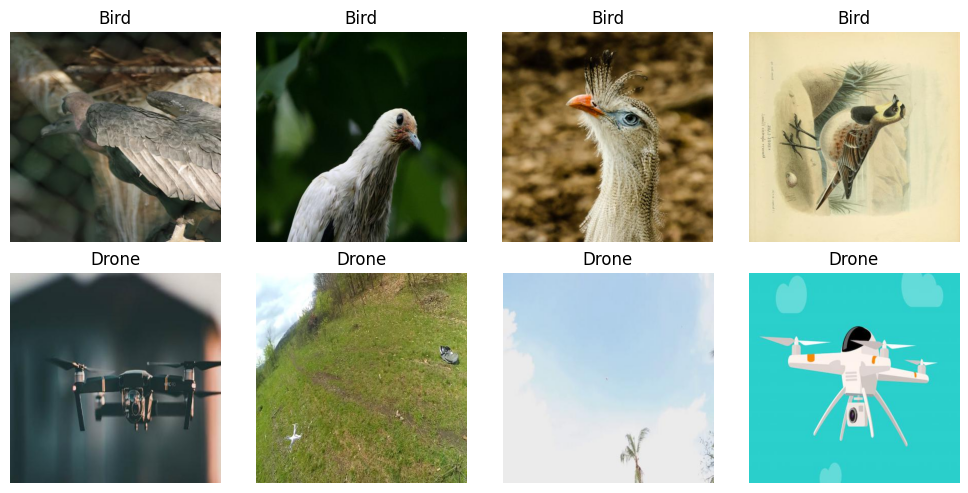

TensorFlow 2.21.0 | GPUs []


In [2]:
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display

SEED = 42
keras.utils.set_random_seed(SEED)
OUT = ROOT / 'bird_drone_results'
OUT.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for name, row in zip(CLASSES, axes):
    paths = sorted((DATA / 'train' / name).glob('*.jpg'))
    for ax, idx in zip(row, rng.choice(len(paths), len(row), replace=False)):
        with Image.open(paths[idx]) as im:
            ax.imshow(im.convert('RGB'))
        ax.set_title(name.title())
        ax.axis('off')
plt.tight_layout()
plt.show()
print('TensorFlow', tf.__version__, '| GPUs', tf.config.list_physical_devices('GPU'))

## 3 · Prepare image batches
Resize RGB images to 224 × 224. The models include normalization and apply random crop, flip, rotation, zoom and brightness changes during training. Keep validation and test images in a fixed order so each prediction matches its label.

In [3]:
SIZE = (224, 224)
def dataset(split, shuffle=False):
    return keras.utils.image_dataset_from_directory(
        DATA / split, class_names=CLASSES, label_mode='int', image_size=SIZE,
        batch_size=32, shuffle=shuffle, seed=SEED
    ).prefetch(tf.data.AUTOTUNE)

valid = dataset('valid')
def image_input():
    inputs = keras.Input((*SIZE, 3))
    x = layers.Rescaling(1/255.)(inputs)
    x = layers.RandomFlip('horizontal')(x)
    x = layers.RandomRotation(0.04, fill_mode='reflect')(x)
    x = layers.RandomZoom(0.08, fill_mode='reflect')(x)
    x = layers.RandomBrightness(0.08, value_range=(0, 1))(x)
    # Random crop during training; center-preserving resize during inference.
    x = layers.RandomCrop(212, 212)(x)
    x = layers.Resizing(*SIZE)(x)
    return inputs, x

Found 442 files belonging to 2 classes.


## 4 · Train the custom CNN
Convolution layers learn visual patterns. Pooling reduces the feature-map size, and dropout helps limit overfitting. Each run saves its lowest-validation-loss checkpoint. Training stops early if validation loss stalls.

In [4]:
def compile_model(model, rate):
    model.compile(optimizer=keras.optimizers.Adam(rate),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])

def fit_stage(model, stage, epochs):
    train = dataset('train', shuffle=True)
    checkpoint = OUT / f'{stage}.keras'
    callbacks = [
        keras.callbacks.ModelCheckpoint(str(checkpoint), monitor='val_loss', save_best_only=True),
        keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
    ]
    start = time.perf_counter()
    history = model.fit(train, validation_data=valid, epochs=epochs, callbacks=callbacks)
    return pd.DataFrame(history.history), time.perf_counter() - start

inputs, x = image_input()
for filters in (32, 64, 128):
    x = layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D()(x)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.35)(x)
cnn = keras.Model(inputs, layers.Dense(2, activation='softmax')(x))
compile_model(cnn, 0.001)
cnn_hist, cnn_time = fit_stage(cnn, 'custom_cnn', 18)

Found 2662 files belonging to 2 classes.
Epoch 1/18
84/84 ━━━━━━━━━━━━━━━━━━━━ 520s 6s/step - accuracy: 0.6871 - loss: 0.6330 - val_accuracy: 0.5317 - val_loss: 0.6540
Epoch 2/18
84/84 ━━━━━━━━━━━━━━━━━━━━ 563s 6s/step - accuracy: 0.7194 - loss: 0.5691 - val_accuracy: 0.5113 - val_loss: 0.6833
Epoch 3/18
84/84 ━━━━━━━━━━━━━━━━━━━━ 518s 6s/step - accuracy: 0.7438 - loss: 0.5331 - val_accuracy: 0.6109 - val_loss: 0.6819
Epoch 4/18
84/84 ━━━━━━━━━━━━━━━━━━━━ 560s 6s/step - accuracy: 0.7446 - loss: 0.5242 - val_accuracy: 0.7149 - val_loss: 0.6011
Epoch 5/18
84/84 ━━━━━━━━━━━━━━━━━━━━ 555s 6s/step - accuracy: 0.7442 - loss: 0.5256 - val_accuracy: 0.7014 - val_loss: 0.6146
Epoch 6/18
84/84 ━━━━━━━━━━━━━━━━━━━━ 514s 6s/step - accuracy: 0.7506 - loss: 0.5111 - val_accuracy: 0.7127 - val_loss: 0.5480
Epoch 7/18
84/84 ━━━━━━━━━━━━━━━━━━━━ 565s 6s/step - accuracy: 0.7656 - loss: 0.4960 - val_accuracy: 0.6810 - val_loss: 0.7586
Epoch 8/18
84/84 ━━━━━━━━━━━━━━━━━━━━ 509s 6s/step - accuracy: 0.7562 

## 5 · Train and fine-tune MobileNetV2
First train the classifier head on frozen ImageNet features. Then unlock the last 30 backbone layers, keeping batch normalization frozen, and train with a smaller learning rate. Retain the better checkpoint across both stages.

In [5]:
inputs, x = image_input()
x = layers.Rescaling(2., offset=-1.)(x)  # MobileNetV2 expects pixels in [-1, 1].
base = keras.applications.MobileNetV2(input_shape=(*SIZE, 3), include_top=False, weights='imagenet')
base.trainable = False
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.25)(x)
mobile = keras.Model(inputs, layers.Dense(2, activation='softmax')(x))
compile_model(mobile, 0.001)
head_hist, head_time = fit_stage(mobile, 'mobile_head', 8)
mobile = keras.models.load_model(OUT / 'mobile_head.keras')
base = next(layer for layer in mobile.layers if isinstance(layer, keras.Model))
base.trainable = True
for i, layer in enumerate(base.layers):
    layer.trainable = i >= len(base.layers) - 30 and not isinstance(layer, layers.BatchNormalization)
compile_model(mobile, 0.00001)
fine_hist, fine_time = fit_stage(mobile, 'mobile_fine', 8)
mobile_stage = 'mobile_fine' if fine_hist.val_loss.min() < head_hist.val_loss.min() else 'mobile_head'
shutil.copyfile(OUT / f'{mobile_stage}.keras', OUT / 'mobilenet.keras')
print('Retained transfer-learning checkpoint:', mobile_stage)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Found 2662 files belonging to 2 classes.
Epoch 1/8
84/84 ━━━━━━━━━━━━━━━━━━━━ 163s 2s/step - accuracy: 0.8805 - loss: 0.2864 - val_accuracy: 0.9457 - val_loss: 0.1403
Epoch 2/8
84/84 ━━━━━━━━━━━━━━━━━━━━ 158s 2s/step - accuracy: 0.9591 - loss: 0.1094 - val_accuracy: 0.9615 - val_loss: 0.1158
Epoch 3/8
84/84 ━━━━━━━━━━━━━━━━━━━━ 202s 2s/step - accuracy: 0.9557 - loss: 0.1011 - val_accuracy: 0.9661 - val_loss: 0.1060
Epoch 4/8
84/84 ━━━━━━━━━━━━━━━━━━━━ 221s 2s/step - accuracy: 0.9718 - loss: 0.0744 - val_accuracy: 0.9683 - val_loss: 0.1028
Epoch 5/8
84/84 ━━━━━━━━━━━━━━━━━━━━ 164s 2s/step - accuracy: 0.9730 - loss: 0.0670 - val_accuracy: 0.9661 - val_loss: 0.0997
Epoch 6/8
84/84 ━━━━━━━━━━━━━━━━━━━━ 200s 2s/step - accuracy: 0.9793 - loss: 0.0623 - val_accuracy: 0.9661 - val_loss: 0.1028
Epoch 7/8
84/84 ━━━━━━━━━━━━━━━━━━━━ 225s 2s/step - accuracy: 0.9835 - loss: 0.0544 - val_accuracy: 0.9548 - val_loss: 0.1095
Epoch 8/8
84/84 ━━━━━━━━━━━━

## 6 · Compare training curves and choose the model
Use validation macro F1 to choose the winner. Macro F1 gives each class equal weight. Ties go to the custom CNN. The test split stays untouched until this decision is fixed.

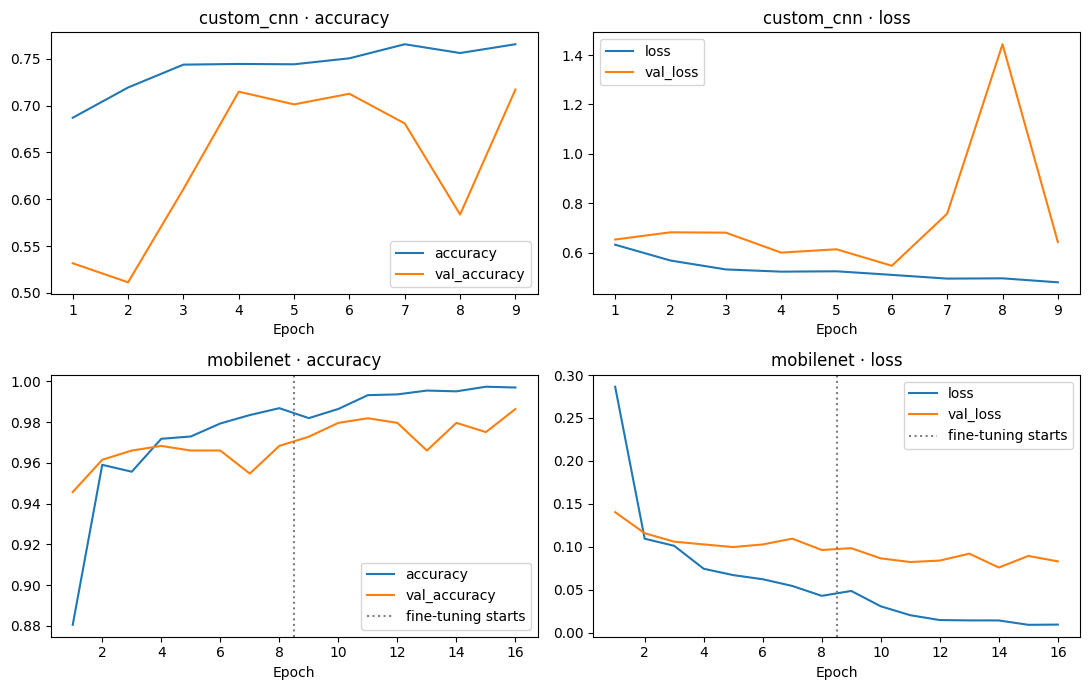

Selected before test evaluation: mobilenet


,validation_macro_f1,validation_accuracy,training_minutes
custom_cnn,0.7094,0.7127,81.2743
mobilenet,0.9796,0.9796,50.9509


In [6]:
histories = {'custom_cnn': cnn_hist, 'mobilenet': pd.concat([head_hist, fine_hist], ignore_index=True)}
seconds = {'custom_cnn': cnn_time, 'mobilenet': head_time + fine_time}
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for row, (name, h) in zip(axes, histories.items()):
    h.to_csv(OUT / f'{name}_history.csv', index=False)
    for ax, metric in zip(row, ['accuracy', 'loss']):
        for key in (metric, 'val_' + metric):
            ax.plot(range(1, len(h)+1), h[key], label=key)
        if name == 'mobilenet':
            ax.axvline(len(head_hist)+0.5, linestyle=':', color='gray', label='fine-tuning starts')
        ax.set(title=f'{name} · {metric}', xlabel='Epoch')
        ax.legend()
plt.tight_layout()
fig.savefig(OUT / 'learning_curves.png')
plt.show()

def score(model, ds):
    actual, predicted = [], []
    for images, labels in ds:
        actual.extend(labels.numpy())
        predicted.extend(model(images, training=False).numpy().argmax(axis=1))
    report = classification_report(actual, predicted, labels=[0, 1], target_names=CLASSES,
                                   output_dict=True, zero_division=0)
    return report, confusion_matrix(actual, predicted, labels=[0, 1])

models = {name: keras.models.load_model(OUT / f'{name}.keras') for name in histories}
rows = {}
for name, model in models.items():
    stats, _ = score(model, valid)
    rows[name] = dict(validation_macro_f1=stats['macro avg']['f1-score'],
                      validation_accuracy=stats['accuracy'], training_minutes=seconds[name]/60)
winner = max(rows, key=lambda name: rows[name]['validation_macro_f1'])
print('Selected before test evaluation:', winner)
display(pd.DataFrame(rows).T.round(4))

## 7 · Evaluate both models on the held-out test images
Rows in each confusion matrix show actual classes, columns show predictions. Recall answers “Of the actual birds, how many were identified?” Precision answers “Of the predicted birds, how many were actually birds?” Inspect both classes and the validation-to-test gap.

Found 215 files belonging to 2 classes.
custom_cnn


,precision,recall,f1-score,support
bird,0.765,0.942,0.844,121.0
drone,0.894,0.628,0.738,94.0
macro avg,0.830,0.785,0.791,215.0
weighted avg,0.821,0.805,0.798,215.0


mobilenet


,precision,recall,f1-score,support
bird,0.992,0.992,0.992,121.0
drone,0.989,0.989,0.989,94.0
macro avg,0.991,0.991,0.991,215.0
weighted avg,0.991,0.991,0.991,215.0


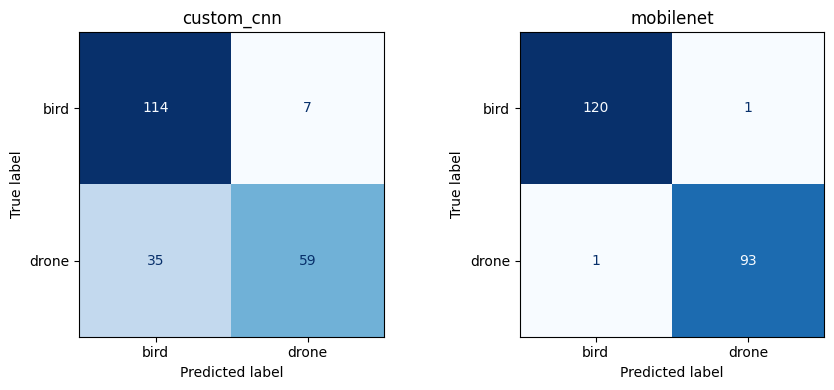

,validation_macro_f1,validation_accuracy,training_minutes,test_accuracy,test_precision,test_recall,test_macro_f1,validation_minus_test_accuracy
custom_cnn,0.7094,0.7127,81.2743,0.8047,0.8295,0.7849,0.7910,-0.0920
mobilenet,0.9796,0.9796,50.9509,0.9907,0.9905,0.9905,0.9905,-0.0111


# Bird or Drone · Model comparison

Selected model: mobilenet. Selection used validation macro F1 before test evaluation.
The selected model achieved 0.980 validation macro F1
and 0.991 test macro F1 on 215 held-out images.
Its validation accuracy minus test accuracy was -0.011.
Precision and recall below are macro averages. Training minutes include checkpoint saving.

            validation_macro_f1  validation_accuracy  training_minutes  test_accuracy  test_precision  test_recall  test_macro_f1  validation_minus_test_accuracy
custom_cnn               0.7094               0.7127           81.2743         0.8047          0.8295       0.7849         0.7910                         -0.0920
mobilenet                0.9796               0.9796           50.9509         0.9907          0.9905       0.9905         0.9905                         -0.0111

These measurements describe the supplied split. Similar backgrounds or related images
can make a split easier than new photographs. The model

In [7]:
test = dataset('test')
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (name, model) in zip(axes, models.items()):
    stats, matrix = score(model, test)
    per_class = pd.DataFrame({key: stats[key] for key in CLASSES + ['macro avg', 'weighted avg']}).T
    print(name)
    display(per_class.round(3))
    per_class.to_csv(OUT / f'{name}_classification_report.csv')
    avg = stats['macro avg']
    rows[name].update(test_accuracy=stats['accuracy'], test_precision=avg['precision'],
                      test_recall=avg['recall'], test_macro_f1=avg['f1-score'],
                      validation_minus_test_accuracy=rows[name]['validation_accuracy']-stats['accuracy'])
    ConfusionMatrixDisplay(matrix, display_labels=CLASSES).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name)
plt.tight_layout()
fig.savefig(OUT / 'confusion_matrices.png')
plt.show()
comparison = pd.DataFrame(rows).T
display(comparison.round(4))
comparison.to_csv(OUT / 'model_comparison.csv')
shutil.copyfile(OUT / f'{winner}.keras', OUT / 'best_model.keras')
best = rows[winner]
report_text = f'''# Bird or Drone · Model comparison

Selected model: {winner}. Selection used validation macro F1 before test evaluation.
The selected model achieved {best["validation_macro_f1"]:.3f} validation macro F1
and {best["test_macro_f1"]:.3f} test macro F1 on {sum(EXPECTED["test"])} held-out images.
Its validation accuracy minus test accuracy was {best["validation_minus_test_accuracy"]:+.3f}.
Precision and recall below are macro averages. Training minutes include checkpoint saving.

{comparison.round(4).to_string()}

These measurements describe the supplied split. Similar backgrounds or related images
can make a split easier than new photographs. The model assumes one of two classes
and may give a confident answer for an unrelated image.
'''
(OUT / 'comparison_report.md').write_text(report_text)
print(report_text)

## 8 · Preview a prediction and export the Streamlit app
The preview uses the same resizing and class order as the app. The app accepts a JPG or PNG and displays the predicted class and its model score.

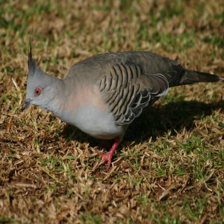

Actual: bird | Prediction: bird | Confidence: 99.5%
Streamlit app written.


In [8]:
sample = next((DATA / 'test' / 'bird').glob('*.jpg'))
with Image.open(sample) as image:
    pixels = tf.image.resize(np.asarray(image.convert('RGB')), SIZE)
    display(image.copy().resize(SIZE))
scores = models[winner](pixels[None], training=False).numpy()[0]
print(f'Actual: bird | Prediction: {CLASSES[scores.argmax()]} | Confidence: {scores.max():.1%}')
(OUT / 'app.py').write_text('from pathlib import Path\nimport numpy as np\nimport streamlit as st\nimport tensorflow as tf\nfrom PIL import Image, ImageOps\n\n@st.cache_resource\ndef load_model():\n    return tf.keras.models.load_model(Path(__file__).with_name("best_model.keras"), compile=False)\n\nst.title("Bird or Drone?")\nst.write("Upload one photograph containing a bird or a drone.")\nphoto = st.file_uploader("Choose a JPG or PNG", type=["jpg", "jpeg", "png"])\nif photo is not None:\n    image = ImageOps.exif_transpose(Image.open(photo)).convert("RGB")\n    st.image(image)\n    pixels = tf.image.resize(np.asarray(image), [224, 224])\n    scores = load_model()(pixels[None], training=False).numpy()[0]\n    choice = int(np.argmax(scores))\n    st.metric(["Bird", "Drone"][choice], f"{scores[choice]:.1%}")\n    st.caption("Model confidence for this image. Unrelated subjects can also receive high scores.")\n')
(OUT / 'requirements.txt').write_text(f'tensorflow=={tf.__version__}\nstreamlit\npillow\nnumpy\n')
print('Streamlit app written.')

## 9 · Results
Run the last cell to download both trained models, the selected deployment model, comparison tables, plots and app. Extract the ZIP. To run the app locally, open a terminal in the extracted folder, install the packages with `python -m pip install -r requirements.txt`, then run `python -m streamlit run app.py`. For deployment, put `app.py`, `requirements.txt` and `best_model.keras` together.

In [9]:
from zipfile import ZIP_DEFLATED
bundle = ROOT / 'Bird_vs_Drone_results.zip'
with ZipFile(bundle, 'w', ZIP_DEFLATED) as archive:
    for path in sorted(OUT.iterdir()):
        if path.is_file() and path.name not in {'mobile_head.keras', 'mobile_fine.keras'}:
            archive.write(path, path.name)
print('Download size:', round(bundle.stat().st_size / 1024**2, 1), 'MB')
files.download(str(bundle))

Download size: 38.7 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>